## 1. Data Loading & Initial Inspection

**Dataset:** US Airport Traffic (February 2011).
We have 221 airports, their geographic coordinates (lat, long), and the volume of traffic (`cnt`).
**Observations:** 
- The dataset is quite clean, with only 1 missing value in `city` and `state`.
- The target variable for analysis is `cnt` (number of flights/aircraft).

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

print("Cargando dataset real de vuelos...")
# Enlace directo a un dataset público (se descarga al instante)
url = "https://raw.githubusercontent.com/plotly/datasets/master/2011_february_us_airport_traffic.csv"

# Cargamos los datos
df = pd.read_csv(url)

print("¡Datos cargados con éxito!\n")
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns.\n")

print("--- Data Types & Non-Null Counts ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())

Cargando dataset real de vuelos...
¡Datos cargados con éxito!

Dataset Shape: 221 rows and 8 columns.

--- Data Types & Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221 entries, 0 to 220
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   iata     221 non-null    object 
 1   airport  221 non-null    object 
 2   city     220 non-null    object 
 3   state    220 non-null    object 
 4   country  221 non-null    object 
 5   lat      221 non-null    float64
 6   long     221 non-null    float64
 7   cnt      221 non-null    int64  
dtypes: float64(2), int64(1), object(5)
memory usage: 13.9+ KB

--- Missing Values ---
iata       0
airport    0
city       1
state      1
country    0
lat        0
long       0
cnt        0
dtype: int64


In [5]:
# 1. Limpieza: Eliminar las filas con valores nulos
df_clean = df.dropna().copy()

# 2. Análisis Univariado: Estadísticas descriptivas de la variable objetivo (cnt)
print("--- Estadísticas del Tráfico Aéreo (cnt) ---")
print(df_clean['cnt'].describe())

# 3. Top 10 aeropuertos con más tráfico
top_airports = df_clean.sort_values(by='cnt', ascending=False).head(10)
print("\n--- Top 10 Aeropuertos con más tráfico ---")
print(top_airports[['airport', 'city', 'state', 'cnt']].to_string(index=False))

--- Estadísticas del Tráfico Aéreo (cnt) ---
count      220.000000
mean      2007.377273
std       3757.945949
min         23.000000
25%        191.250000
50%        497.500000
75%       1645.500000
max      25129.000000
Name: cnt, dtype: float64

--- Top 10 Aeropuertos con más tráfico ---
                          airport              city state   cnt
     Chicago O'Hare International           Chicago    IL 25129
William B Hartsfield-Atlanta Intl           Atlanta    GA 21925
  Dallas-Fort Worth International Dallas-Fort Worth    TX 20662
 Phoenix Sky Harbor International           Phoenix    AZ 17290
                      Denver Intl            Denver    CO 13781
     George Bush Intercontinental           Houston    TX 13223
      San Francisco International     San Francisco    CA 12016
        Los Angeles International       Los Angeles    CA 11797
            Orlando International           Orlando    FL 10536
  Charlotte/Douglas International         Charlotte    NC 10490


C:\Users\Laura\AppData\Local\Temp\ipykernel_7104\4134260170.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_airports, x='cnt', y='airport', palette='viridis')


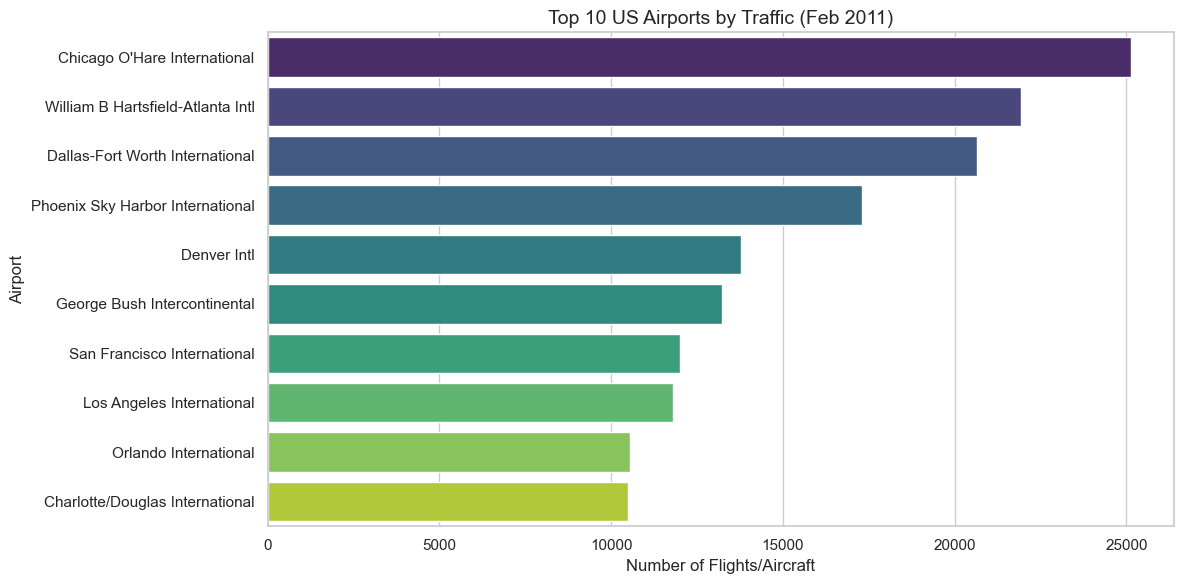

In [6]:
plt.figure(figsize=(12, 6))

# Gráfico de barras
sns.barplot(data=top_airports, x='cnt', y='airport', palette='viridis')

plt.title('Top 10 US Airports by Traffic (Feb 2011)', fontsize=14)
plt.xlabel('Number of Flights/Aircraft')
plt.ylabel('Airport')
plt.tight_layout()

# Guardar la imagen
import os
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/01_top_airports.png', dpi=300, bbox_inches='tight')

plt.show()

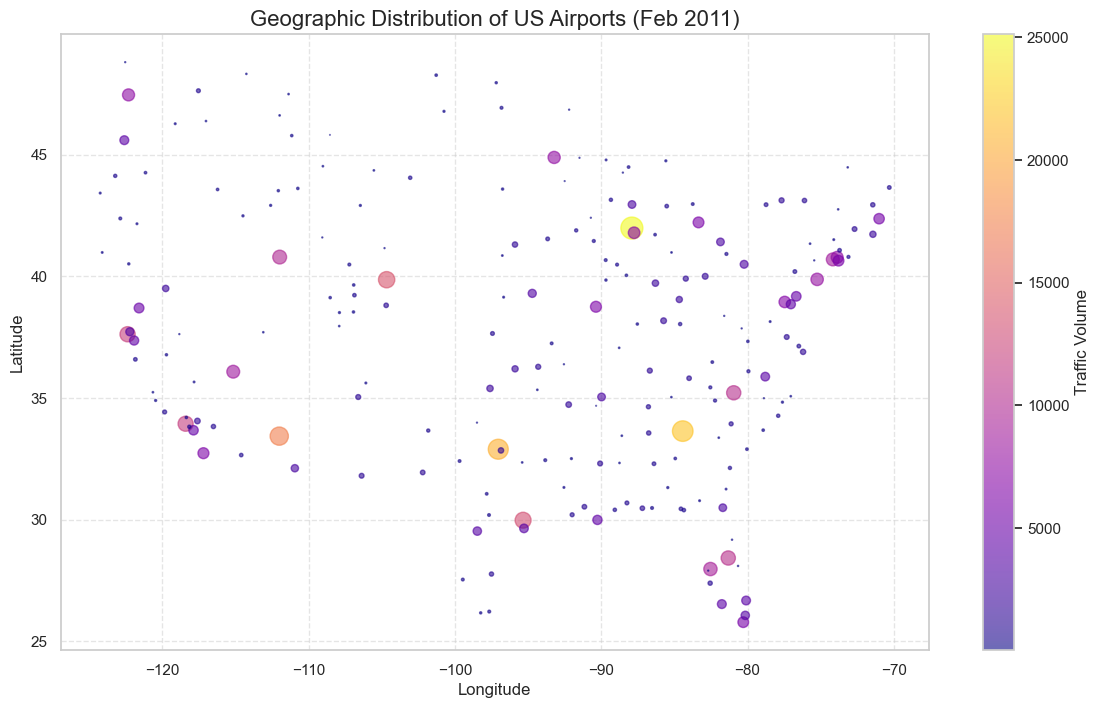

In [7]:
plt.figure(figsize=(14, 8))

# Usamos un mapa de color para representar el tráfico (cnt)
scatter = plt.scatter(df_clean['long'], df_clean['lat'], 
                      s=df_clean['cnt']/100, # El tamaño del punto depende del tráfico
                      alpha=0.6, 
                      c=df_clean['cnt'], 
                      cmap='plasma')

plt.colorbar(scatter, label='Traffic Volume')
plt.title('Geographic Distribution of US Airports (Feb 2011)', fontsize=16)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)

# Guardar la imagen
plt.savefig('../reports/02_airport_map.png', dpi=300, bbox_inches='tight')

plt.show()